<a href="https://colab.research.google.com/github/Mitali-Kambli20/CSL701-CE13_Machine-Learning-Lab/blob/main/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Mitali Manohar Kambli

Batch : CE1


Roll Number : CE13



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:

# Task 1: Import libraries and load dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report
)

# Load Palmer Penguins dataset
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(url)

# Display dataset
print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())


First five rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Dataset shape: (344, 8)

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Missing values:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:

# Task 2: Select features and preprocess

# Support alternative feature names
if "culmen_length_mm" in df.columns:
    length_col = "culmen_length_mm"
    depth_col = "culmen_depth_mm"
else:
    length_col = "bill_length_mm"
    depth_col = "bill_depth_mm"

features = [length_col, depth_col, "flipper_length_mm", "body_mass_g"]

# Remove rows with missing species
df = df.dropna(subset=["species"]).copy()

# Convert feature columns to numeric and fill missing values
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

X = df[features]
y = df["species"]

# Encode target labels
encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Selected features:", features)
print("Species classes:", encoder.classes_)
print("Missing values after preprocessing:\n", X.isnull().sum())
print("Total samples:", len(X))


Selected features: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Species classes: ['Adelie' 'Chinstrap' 'Gentoo']
Missing values after preprocessing:
 bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64
Total samples: 344


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [3]:

# Task 3: Split the data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 275
Testing samples: 69


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [4]:

# Task 4: Train CART classifier

cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_model.fit(X_train, y_train)

# Predict species on test data
y_pred_cart = cart_model.predict(X_test)

print("CART model trained successfully!")


CART model trained successfully!


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [5]:

# Task 5: Evaluate CART model

print("CART Accuracy:", accuracy_score(y_test, y_pred_cart))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cart))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_cart,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


CART Accuracy: 0.9855072463768116

Confusion Matrix:
[[29  0  1]
 [ 0 14  0]
 [ 0  0 25]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       0.96      1.00      0.98        25

    accuracy                           0.99        69
   macro avg       0.99      0.99      0.99        69
weighted avg       0.99      0.99      0.99        69



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


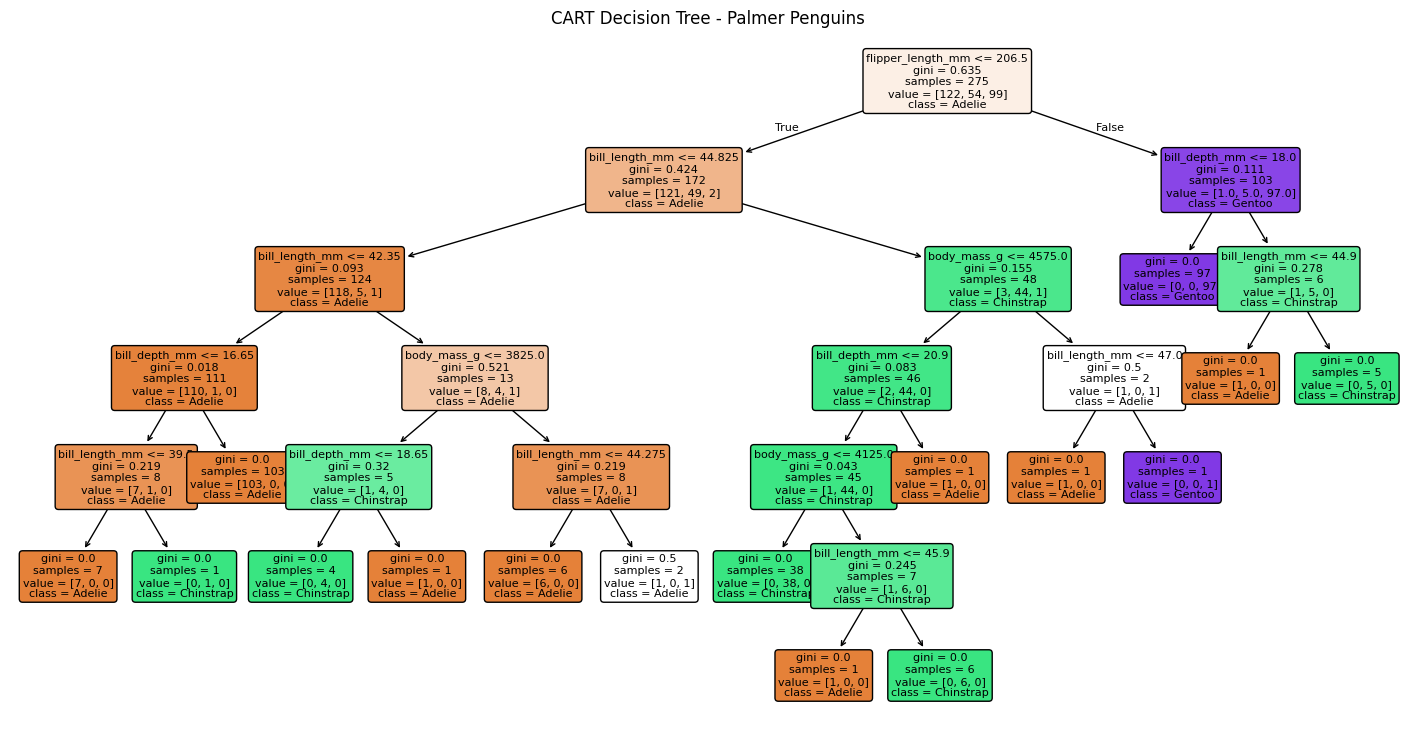

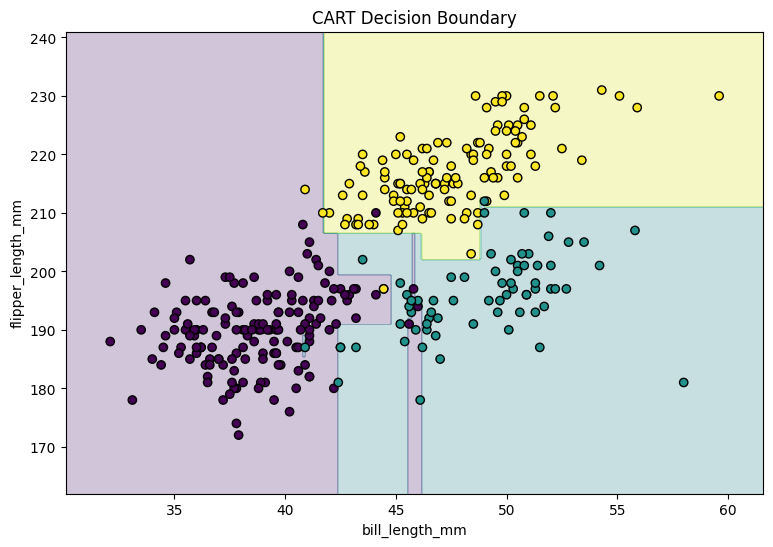

In [6]:

# Task 6A: Visualize the CART tree

plt.figure(figsize=(18, 9))
plot_tree(
    cart_model,
    feature_names=features,
    class_names=encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("CART Decision Tree - Palmer Penguins")
plt.show()


# Task 6B: Train a 2D Decision Tree

features_2d = [length_col, "flipper_length_mm"]
X_2d = X[features_2d]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cart_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
cart_2d.fit(X_train_2d, y_train_2d)

# Create a grid for the decision boundary
x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 10, X_2d.iloc[:, 1].max() + 10

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    features_2d[0]: xx.ravel(),
    features_2d[1]: yy.ravel()
})

Z = cart_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
plt.scatter(
    X_2d.iloc[:, 0], X_2d.iloc[:, 1],
    c=y, cmap="viridis", edgecolors="black"
)
plt.xlabel(features_2d[0])
plt.ylabel(features_2d[1])
plt.title("CART Decision Boundary")
plt.show()


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

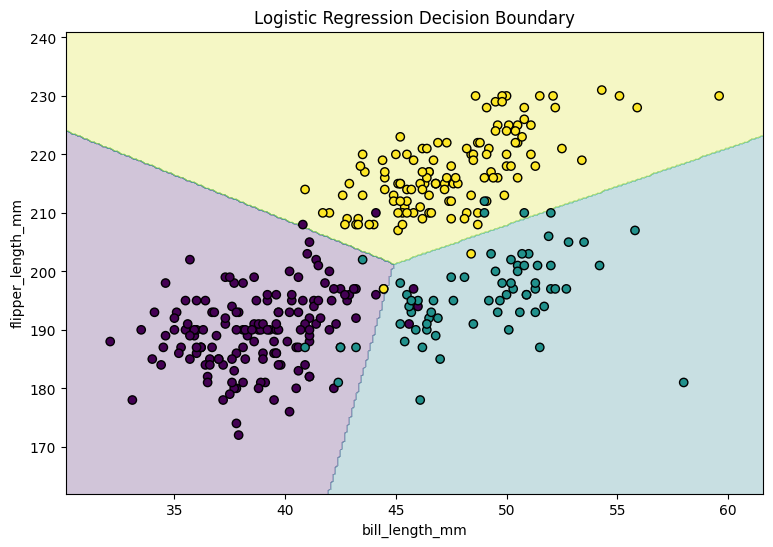

In [7]:

# Task 7: Logistic Regression with a linear boundary

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_2d)
X_test_scaled = scaler.transform(X_test_2d)

log_model = LogisticRegression(max_iter=2000)
log_model.fit(X_train_scaled, y_train_2d)

y_pred_log = log_model.predict(X_test_scaled)

# Create grid in original feature units
grid_scaled = scaler.transform(grid)
Z_log = log_model.predict(grid_scaled).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_log, alpha=0.25, cmap="viridis")
plt.scatter(
    X_2d.iloc[:, 0], X_2d.iloc[:, 1],
    c=y, cmap="viridis", edgecolors="black"
)
plt.xlabel(features_2d[0])
plt.ylabel(features_2d[1])
plt.title("Logistic Regression Decision Boundary")
plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

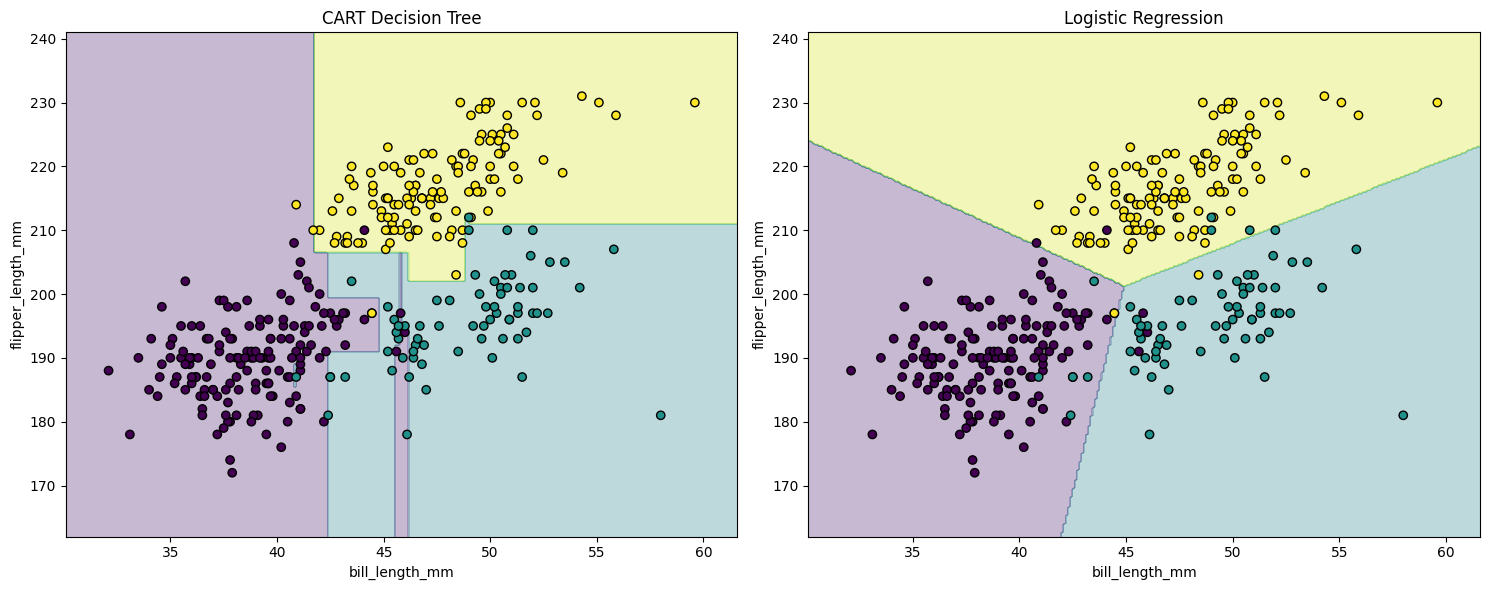

In [8]:

# Task 8: Compare decision boundaries

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# CART boundary
axes[0].contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
axes[0].scatter(
    X_2d.iloc[:, 0], X_2d.iloc[:, 1],
    c=y, cmap="viridis", edgecolors="black"
)
axes[0].set_title("CART Decision Tree")
axes[0].set_xlabel(features_2d[0])
axes[0].set_ylabel(features_2d[1])

# Logistic Regression boundary
axes[1].contourf(xx, yy, Z_log, alpha=0.3, cmap="viridis")
axes[1].scatter(
    X_2d.iloc[:, 0], X_2d.iloc[:, 1],
    c=y, cmap="viridis", edgecolors="black"
)
axes[1].set_title("Logistic Regression")
axes[1].set_xlabel(features_2d[0])
axes[1].set_ylabel(features_2d[1])

plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [9]:

# Task 9: Compare model performance

# Predictions on the same test set
y_pred_cart_2d = cart_2d.predict(X_test_2d)
y_pred_log = log_model.predict(X_test_scaled)

print("========== CART CLASSIFIER ==========")
print("Accuracy:", accuracy_score(y_test_2d, y_pred_cart_2d))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_2d, y_pred_cart_2d))
print("\nClassification Report:")
print(classification_report(
    y_test_2d, y_pred_cart_2d,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

print("\n========== LOGISTIC REGRESSION ==========")
print("Accuracy:", accuracy_score(y_test_2d, y_pred_log))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_2d, y_pred_log))
print("\nClassification Report:")
print(classification_report(
    y_test_2d, y_pred_log,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


========== CART CLASSIFIER ==========
Accuracy: 0.927536231884058

Confusion Matrix:
[[29  0  1]
 [ 3 11  0]
 [ 1  0 24]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.88      0.97      0.92        30
   Chinstrap       1.00      0.79      0.88        14
      Gentoo       0.96      0.96      0.96        25

    accuracy                           0.93        69
   macro avg       0.95      0.90      0.92        69
weighted avg       0.93      0.93      0.93        69


========== LOGISTIC REGRESSION ==========
Accuracy: 0.9710144927536232

Confusion Matrix:
[[29  0  1]
 [ 1 13  0]
 [ 0  0 25]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.97      0.97      0.97        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       0.96      1.00      0.98        25

    accuracy                           0.97        69
   macro avg       0.98      0.97      0.97      

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.